# AP 155 Lab Exercise
---
## Exercise 12: More Integration

_Instructions_: 
- **Problem 1**: Figure: Diffraction Pattern, discussion: Explain the figure
- **Problem 2**: Figure: Gamma Function, discussion: *What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?*
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Lunas, Bryce Enrico
- _Student No._: 2024-01596
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="diffraction_pattern.png" alt="Diffraction Pattern" width="45%"> <img src="importance_sampling.png" alt="Importance Sampling Plot" width="45%">

**Figure 1.** (Left) Numerical simulation results. Two-dimensional intensity distribution of a light diffraction pattern showing concentric Airy rings and a high-intensity central maximum resulting from monochromatic light passing through a circular aperture. 

**Figure 2.** (Right) Importance sampling probability density function $p(x)$ overlaid with target distribution $f(x)$, illustrating sample point concentration in high-value integrand regions to minimize variance.

### Report discussion

a) Figure 1 displays a two-dimensional intensity distribution of a light diffraction pattern, characterized by a bright central spot surrounded by concentric circular fringes. Additionally, the sharp central peak represents the zero-order maximum (constructive interference), while the decaying ring intensity illustrates higher-order diffraction maxima separated by dark regions of destructive interference.

b) Our current version uses Importance Sampling, which samples random points according to a specific probability density function p(x) tailored to the integrand's shape, whereas in the previous session, we used Standard Monte Carlo integration with uniform sampling. Moreover, by concentrating sample points in regions where the integrand exhibits high values or significant variability, Importance Sampling substantially reduces estimator variance and accelerates convergence for an equivalent sample count. However, applying this technique requires selecting a sampling distribution p(x) that closely mirrors the target function f(x) without vanishing where f(x) is non-zero, preventing extreme weight spikes or infinite variance. Furthermore, the proposal distribution p(x) must be strictly positive across the entire domain and properly normalized to integrate to 1, ensuring the resulting numerical estimate remains completely unbiased.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Diffraction limit of a telescope

![Screenshot 2026-11-09 at 5.08.50 PM.png](DiffLimitTelescopeNeumann5-4.png)


Hint 1: You may find it useful to know that $\lim_{x→0} J_1(x)/x = 1/2$ 

Hint 2: The central
spot in the diffraction pattern is so bright that it may be difficult to see the rings around
it on the computer screen. If you run into this problem a simple way to deal with it is to
use one of the other color schemes for density plots described in Section 3.3. The “hot”
scheme works well. For a more sophisticated solution to the problem, the imshow function has an additional argument vmax that allows you to set the value that corresponds
to the brightest point in the plot. For instance, if you say `imshow(x,vmax=0.1)`, then elements in x with value 0.1, or any greater value, will produce the brightest (most positive) color on the screen. By lowering the `vmax` value, you can reduce the total range of
values between the minimum and maximum brightness, and hence increase the sensitivity of the plot, making subtle details visible. (There is also a `vmin` argument that can
be used to set the value that corresponds to the dimmest (most negative) color.) For this
exercise a value of `vmax=0.01` appears to work well.

Report discussion: Explain the figure

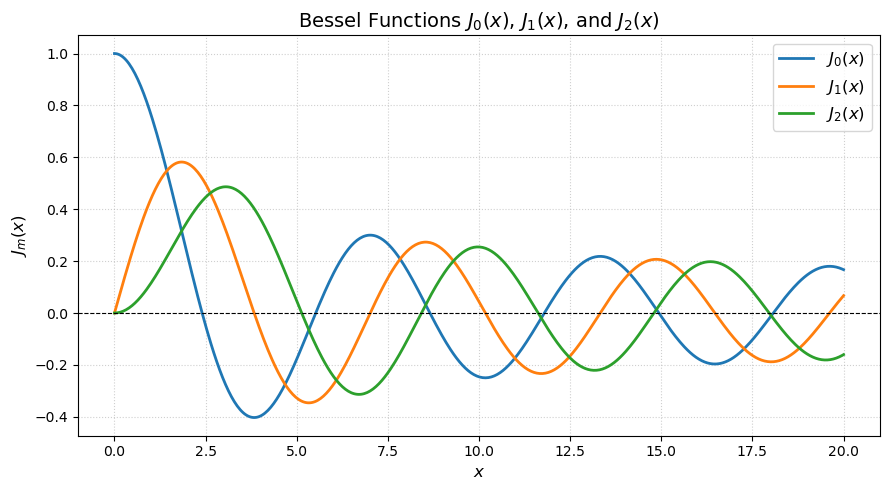

In [2]:
# a)

import numpy as np
import matplotlib.pyplot as plt
import math

def bessel_j(m, x, N=1000):
    """
    Bessel function of the first kind J_m(x) via its integral representation

        J_m(x) = (1/pi) * integral_0^pi cos(m*theta - x*sin(theta)) dtheta

    evaluated with Simpson's rule.

    Parameters
    ----------
    m : int
        Non-negative order of the Bessel function.
    x : float or array-like
        Argument(s) at which to evaluate the function.
    N : int
        Number of integration slices (must be even).

    Returns
    -------
    float or ndarray
        J_m(x), with the same shape as x.
    """
    if N % 2:
        raise ValueError("N must be even for Simpson's rule.")

    x = np.asarray(x, dtype=float)
    theta = np.linspace(0.0, np.pi, N + 1)
    h = np.pi / N

    f = np.cos(m * theta.reshape(-1, *[1] * x.ndim) - x * np.sin(theta).reshape(-1, *[1] * x.ndim))

    weights = np.ones(N + 1)
    weights[1:-1:2] = 4
    weights[2:-1:2] = 2

    integral = np.tensordot(weights, f, axes=1) * h / 3
    return integral / np.pi

x_vals = np.linspace(0, 20, 500)
orders = (0, 1, 2)

# Plot
fig, ax = plt.subplots(figsize=(9, 5))
for m in orders:
    ax.plot(x_vals, bessel_j(m, x_vals), label=rf"$J_{m}(x)$", linewidth=2)

ax.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax.set_title("Bessel Functions $J_0(x)$, $J_1(x)$, and $J_2(x)$", fontsize=14)
ax.set_xlabel("$x$", fontsize=12)
ax.set_ylabel("$J_m(x)$", fontsize=12)
ax.legend(fontsize=12)
ax.grid(True, linestyle=":", alpha=0.6)
fig.tight_layout()
plt.show()

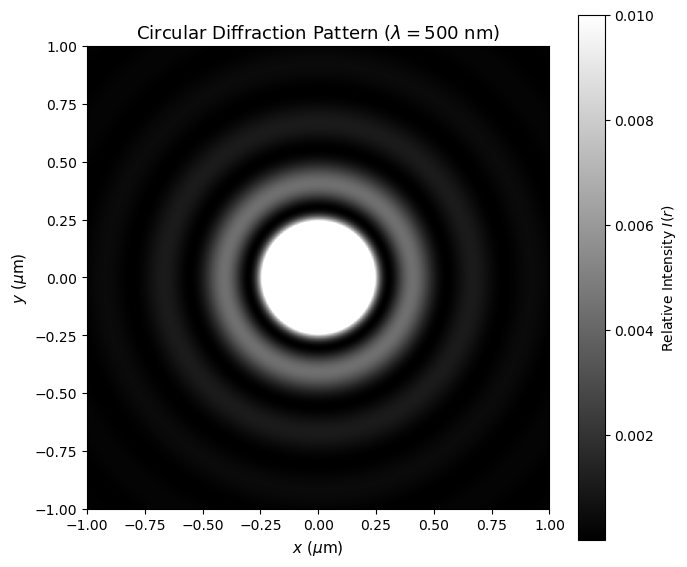

In [9]:
# b)

import numpy as np
import matplotlib.pyplot as plt
import math

WAVELENGTH = 500e-9   # m
GRID_LIMIT = 1e-6     # m (plot spans -1 µm to 1 µm)
POINTS = 300          # grid resolution per axis


def bessel_j(m, x, N=1000, chunk=5000):
    """
    Bessel function J_m(x) from its integral representation,
    evaluated with Simpson's rule:

        J_m(x) = (1/pi) * integral_0^pi cos(m*theta - x*sin(theta)) dtheta

    Works on scalars or arrays of any shape. Points are processed in chunks
    to keep memory use bounded (an (N+1) x len(x) array would be ~720 MB here).
    """
    if N % 2:
        raise ValueError("N must be even for Simpson's rule.")

    x = np.asarray(x, dtype=float)
    theta = np.linspace(0.0, np.pi, N + 1)[:, None]  # column vector
    h = np.pi / N

    weights = np.ones(N + 1)
    weights[1:-1:2] = 4
    weights[2:-1:2] = 2

    flat = x.ravel()
    out = np.empty_like(flat)
    for start in range(0, flat.size, chunk):
        xc = flat[start:start + chunk]
        f = np.cos(m * theta - xc * np.sin(theta))  # shape (N+1, len(xc))
        out[start:start + chunk] = weights @ f

    return (out * h / 3 / np.pi).reshape(x.shape)

def intensity(r, wavelength=WAVELENGTH):
    """
    Relative intensity I(r) = (J_1(k r) / (k r))^2.
    At r = 0 the limit J_1(x)/x -> 1/2 is used.
    """
    kr = (2 * np.pi / wavelength) * np.asarray(r, dtype=float)

    ratio = np.full_like(kr, 0.5)
    nonzero = kr != 0
    ratio[nonzero] = bessel_j(1, kr[nonzero]) / kr[nonzero]
    return ratio**2

axis = np.linspace(-GRID_LIMIT, GRID_LIMIT, POINTS)
X, Y = np.meshgrid(axis, axis)
I = intensity(np.hypot(X, Y))

# Plot
extent_um = GRID_LIMIT * 1e6
fig, ax = plt.subplots(figsize=(7, 6))
img = ax.imshow(
    I,
    extent=[-extent_um, extent_um, -extent_um, extent_um],
    cmap="gray",
    vmax=0.01,  # saturate the bright center to show the diffraction rings
    origin="lower",
)
fig.colorbar(img, ax=ax, label="Relative Intensity $I(r)$")
ax.set_title(r"Circular Diffraction Pattern ($\lambda = 500\text{ nm}$)", fontsize=13)
ax.set_xlabel(r"$x\ (\mu\text{m})$", fontsize=11)
ax.set_ylabel(r"$y\ (\mu\text{m})$", fontsize=11)
fig.tight_layout()
plt.savefig("diffraction_pattern.png", bbox_inches="tight", dpi=300)
plt.show()

### Problem 2: Integration via Monte Carlo with Importance sampling

Evaluate the gamma function for $z\in [1,5]$ $$ \Gamma(z) = \int_{0}^{\infty} t^{z-1} e^{-t} \, dt $$. Plot the function using your integration method vs `scipy.special.gamma` (two curves)

Use monte carlo method with importance sampling, by recasting the integral into the form 

$$ \int f(x)dx = \int g(x)p(x)dx, \ \  g(x) = \frac{f(x)}{p(x)}$$



Report discussion: What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?

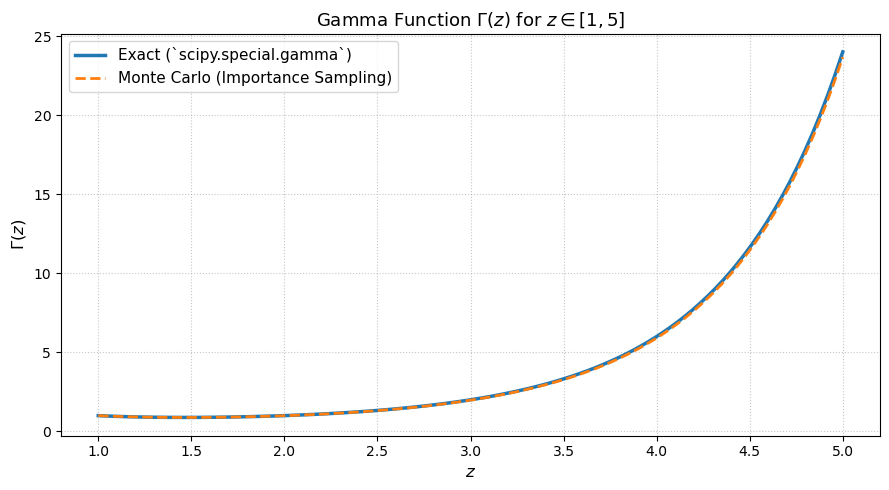

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.special import gamma as scipy_gamma

def gamma_monte_carlo(z, N=100_000, chunk=20_000, seed=None):
    """
    Estimate Gamma(z) = integral_0^inf t^(z-1) exp(-t) dt by Monte Carlo
    with importance sampling.

    Sampling density:  p(t) = exp(-t),  t >= 0
    Remaining factor:  g(t) = f(t) / p(t) = t^(z-1)
    Estimate:          Gamma(z) ~ mean(g(t_i)),  t_i ~ Exp(1)

    Parameters
    ----------
    z : float or array-like
        Argument(s) of the Gamma function (z > 0).
    N : int
        Number of random samples.
    chunk : int
        Samples processed at a time, to bound memory use.
    seed : int or None
        Seed for reproducibility (None gives a different draw each run).
    """
    rng = np.random.default_rng(seed)
    z = np.asarray(z, dtype=float)
    exponent = z.ravel() - 1.0
    total = np.zeros_like(exponent)

    for start in range(0, N, chunk):
        t = rng.exponential(scale=1.0, size=min(chunk, N - start))
        total += (t[:, None] ** exponent).sum(axis=0)

    return (total / N).reshape(z.shape)

# Gamma(z) for z in [1, 5]
z_vals = np.linspace(1.0, 5.0, 100)
gamma_mc = gamma_monte_carlo(z_vals, N=200_000)
gamma_exact = scipy_gamma(z_vals)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(z_vals, gamma_exact, label="Exact (`scipy.special.gamma`)",
        linewidth=2.5, color="tab:blue")
ax.plot(z_vals, gamma_mc, label="Monte Carlo (Importance Sampling)",
        linestyle="--", linewidth=2, color="tab:orange")

ax.set_title(r"Gamma Function $\Gamma(z)$ for $z \in [1, 5]$", fontsize=13)
ax.set_xlabel("$z$", fontsize=12)
ax.set_ylabel(r"$\Gamma(z)$", fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, linestyle=":", alpha=0.7)
fig.tight_layout()
plt.savefig("importance_sampling.png", bbox_inches="tight", dpi=300)
plt.show()